# Spaceship Titanic: Predicting Who Was Transported

This notebook explores the passenger data, fills selected missing values, and trains a classifier to predict whether each passenger was transported. Passenger groups are kept together during validation so members of one travel group do not appear in both a training fold and its validation fold.

## Table of Contents

1. [Load the data](#1-load-the-data)
2. [Review the data](#2-review-the-data)
3. [Explore passenger patterns](#3-explore-passenger-patterns)
4. [Create group and cabin features](#4-create-group-and-cabin-features)
5. [Handle missing values](#5-handle-missing-values)
6. [Build the model matrix](#6-build-the-model-matrix)
7. [Compare models and train the final model](#7-compare-models-and-train-the-final-model)
8. [Create the submission](#8-create-the-submission)

## 1. Load the data

The notebook expects `train.csv` and `test.csv` in the current working directory.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train= pd.read_csv('../train.csv')
test= pd.read_csv('../test.csv')

## 2. Review the data

Check sample rows, column types, summary statistics, and missing values before feature engineering.

In [3]:
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [5]:
train.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [6]:
train.describe(include="object")

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name
count,8693,8492,8476,8494,8511,8490,8493
unique,8693,3,2,6560,3,2,8473
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Gollux Reedall
freq,1,4602,5439,8,5915,8291,2


In [7]:
train.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

## 3. Explore passenger patterns

These plots and cross-tabs examine passenger destinations, home planets, and the relationship between the two.

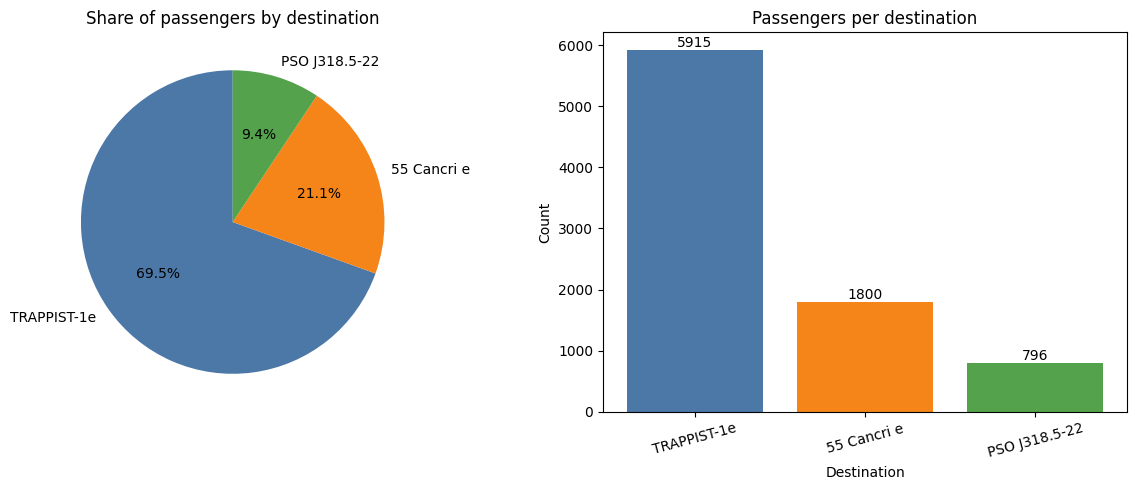

In [8]:

counts = train['Destination'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
            colors=['#4C78A8', '#F58518', '#54A24B'])
axes[0].set_title('Share of passengers by destination')

# Bar chart
bars = axes[1].bar(counts.index, counts.values, color=['#4C78A8', '#F58518', '#54A24B'])
axes[1].bar_label(bars)                      # show the count on each bar
axes[1].set_title('Passengers per destination')
axes[1].set_xlabel('Destination')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

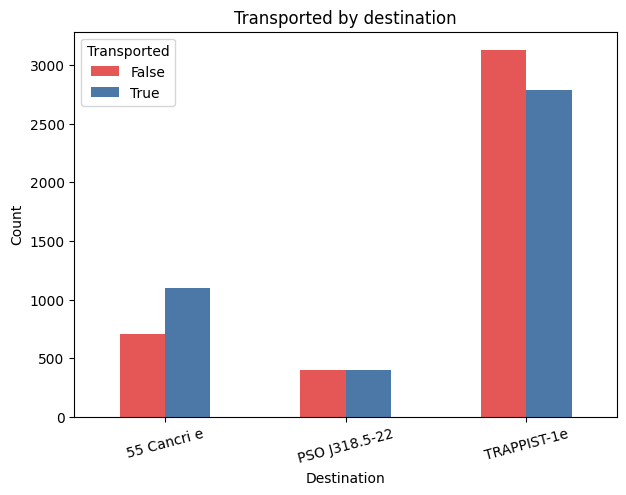

In [9]:
pd.crosstab(train['Destination'], train['Transported']).plot(
    kind='bar', figsize=(7, 5), color=['#E45756', '#4C78A8'])
plt.title('Transported by destination')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.legend(title='Transported')
plt.show()

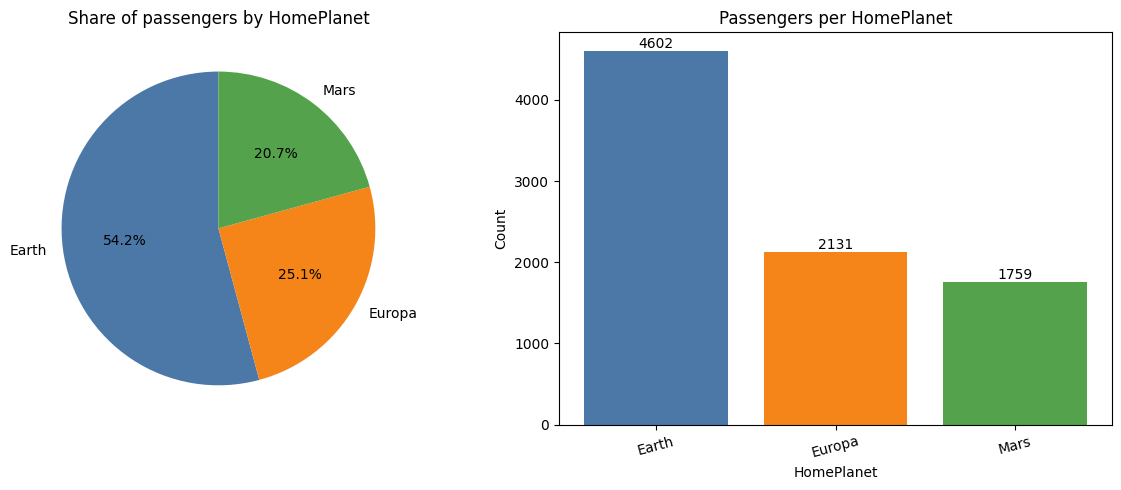

In [10]:

counts = train['HomePlanet'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
            colors=['#4C78A8', '#F58518', '#54A24B'])
axes[0].set_title('Share of passengers by HomePlanet')

# Bar chart
bars = axes[1].bar(counts.index, counts.values, color=['#4C78A8', '#F58518', '#54A24B'])
axes[1].bar_label(bars)                      # show the count on each bar
axes[1].set_title('Passengers per HomePlanet')
axes[1].set_xlabel('HomePlanet')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

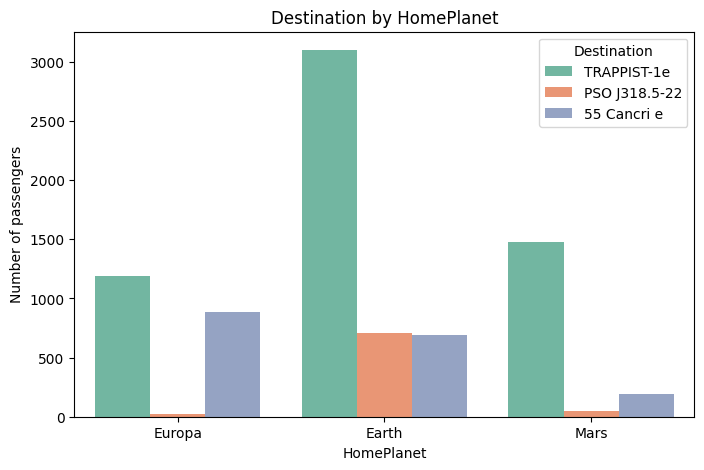

In [11]:

plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='HomePlanet', hue='Destination', palette='Set2')
plt.title('Destination by HomePlanet')
plt.ylabel('Number of passengers')
plt.show()

In [12]:
print(pd.crosstab(train['Destination'], train['HomePlanet'], normalize='index').round(2))
print(pd.crosstab(train['HomePlanet'], train['Destination'], normalize='index').round(2))

HomePlanet     Earth  Europa  Mars
Destination                       
55 Cancri e     0.39    0.50  0.11
PSO J318.5-22   0.91    0.02  0.06
TRAPPIST-1e     0.54    0.21  0.26
Destination  55 Cancri e  PSO J318.5-22  TRAPPIST-1e
HomePlanet                                          
Earth               0.15           0.16         0.69
Europa              0.42           0.01         0.57
Mars                0.11           0.03         0.86


## 4. Create group and cabin features

`PassengerId` provides a travel-group identifier. `Cabin` is split into deck, cabin number, and side so these patterns can be inspected and used in imputation.

In [13]:
for df in [train, test]:
    df['Group'] = df['PassengerId'].str[:4]
    df['GroupSize'] = df.groupby('Group')['PassengerId'].transform('count')

    cabin_parts = df['Cabin'].str.split('/', expand=True)
    df['Deck'] = cabin_parts[0]
    df['CabinNum'] = pd.to_numeric(cabin_parts[1])
    df['Side'] = cabin_parts[2]


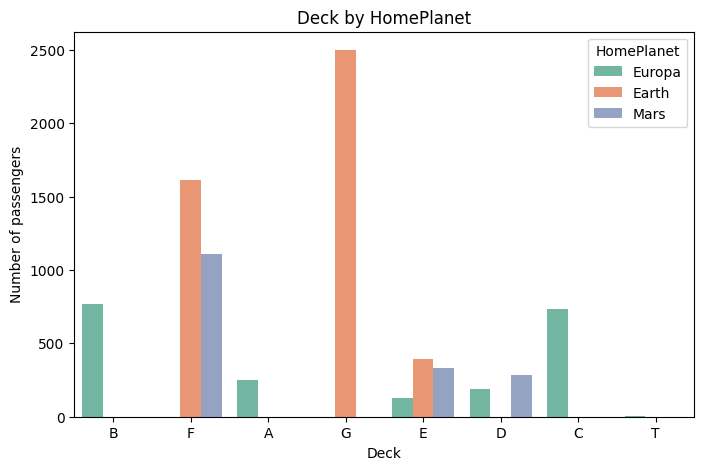

In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='Deck', hue='HomePlanet', palette='Set2')
plt.title('Deck by HomePlanet')
plt.ylabel('Number of passengers')
plt.show()

In [15]:
# counts
counts = pd.crosstab(train['Deck'], train['HomePlanet'])
print(counts)

# row percentages (what share of each deck comes from each planet)
pct = (pd.crosstab(train['Deck'], train['HomePlanet'], normalize='index') * 100).round(1)
print(pct)

HomePlanet  Earth  Europa  Mars
Deck                           
A               0     252     0
B               0     766     0
C               0     734     0
D               0     186   282
E             395     128   330
F            1614       0  1110
G            2498       0     0
T               0       4     0
HomePlanet  Earth  Europa  Mars
Deck                           
A             0.0   100.0   0.0
B             0.0   100.0   0.0
C             0.0   100.0   0.0
D             0.0    39.7  60.3
E            46.3    15.0  38.7
F            59.3     0.0  40.7
G           100.0     0.0   0.0
T             0.0   100.0   0.0


In [16]:
# counts
counts = pd.crosstab(train['GroupSize'], train['Destination'])
print(counts)

# row percentages (what share of each deck comes from each planet)
pct = (pd.crosstab(train['GroupSize'], train['Destination'], normalize='index') * 100).round(1)
print(pct)

Destination  55 Cancri e  PSO J318.5-22  TRAPPIST-1e
GroupSize                                           
1                    843            560         3299
2                    438             97         1105
3                    209             67          731
4                    110             17          279
5                     76             10          173
6                     51             14          106
7                     59             14          150
8                     14             17           72
Destination  55 Cancri e  PSO J318.5-22  TRAPPIST-1e
GroupSize                                           
1                   17.9           11.9         70.2
2                   26.7            5.9         67.4
3                   20.8            6.7         72.6
4                   27.1            4.2         68.7
5                   29.3            3.9         66.8
6                   29.8            8.2         62.0
7                   26.5            6.3       

In [17]:
def group_check(df, col):
    k = df.dropna(subset=[col, 'Group']).copy()
    n    = k.groupby('Group')[col].transform('count')            # known values in the group
    same = k.groupby(['Group', col])[col].transform('count')     # how many share my value
    m = n > 1
    within = ((same - 1) / (n - 1))[m].mean()                    # match rate with companions
    p = k[col].value_counts(normalize=True)
    random_ = (p ** 2).sum()                                     # match rate for two random passengers
    print(f'{col:12s} companions match: {within*100:5.1f}%   random pair: {random_*100:5.1f}%')

raw = train.copy()

for col in ['Deck', 'Side', 'CabinNum', 'Destination', 'HomePlanet']:
    group_check(raw, col)

Deck         companions match:  75.8%   random pair:  23.0%
Side         companions match: 100.0%   random pair:  50.0%
CabinNum     companions match:  75.9%   random pair:   0.1%
Destination  companions match:  57.6%   random pair:  53.6%
HomePlanet   companions match: 100.0%   random pair:  40.0%


In [18]:
raw['GroupNum'] = raw['Group'].astype(int)
raw['CabinNum'] = pd.to_numeric(raw['CabinNum'])
print(raw.groupby('Deck').apply(lambda d: d['GroupNum'].corr(d['CabinNum'])).round(2))

Deck
A    0.98
B    0.99
C    0.99
D    1.00
E    1.00
F    1.00
G    1.00
T    0.66
dtype: float64


C:\Users\ogunt\AppData\Local\Temp\ipykernel_14040\1944653059.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(raw.groupby('Deck').apply(lambda d: d['GroupNum'].corr(d['CabinNum'])).round(2))


## 5. Handle missing values

### Check destination and home-planet patterns

The next cells inspect whether the available features support the proposed imputations before applying them.

In [19]:
known = train.dropna(subset=['Destination'])      # train from before the Destination fill
mode_dest = known['Destination'].mode()[0]
print('Baseline (always', mode_dest + '):', round((known['Destination'] == mode_dest).mean() * 100, 1), '%')

for keys in (['HomePlanet'], ['Deck'], ['CryoSleep'], ['HomePlanet', 'Deck'], ['HomePlanet', 'CryoSleep']):
    sub = known.dropna(subset=keys)
    pred = sub.groupby(keys)['Destination'].transform(lambda s: s.mode()[0])
    print(keys, ':', round((pred == sub['Destination']).mean() * 100, 1), '%')

Baseline (always TRAPPIST-1e): 69.5 %
['HomePlanet'] : 69.3 %
['Deck'] : 69.6 %
['CryoSleep'] : 69.5 %
['HomePlanet', 'Deck'] : 69.4 %
['HomePlanet', 'CryoSleep'] : 69.3 %


In [20]:
known = train.dropna(subset=['Deck', 'Destination', 'HomePlanet'])

deck_map = known.groupby('Deck')['HomePlanet'].agg(lambda s: s.mode()[0])
dest_map = known.groupby('Destination')['HomePlanet'].agg(lambda s: s.mode()[0])

In [21]:
pred_deck = known['Deck'].map(deck_map)
pred_dest = known['Destination'].map(dest_map)
agree = pred_deck == pred_dest

print('Rows where the two agree:', round(agree.mean() * 100, 1), '%')
print('Accuracy when they agree:', round((pred_deck[agree] == known.loc[agree, 'HomePlanet']).mean() * 100, 1), '%')
print('Accuracy of deck alone:  ', round((pred_deck == known['HomePlanet']).mean() * 100, 1), '%')
print('Accuracy of global mode: ', round((known['HomePlanet'] == known['HomePlanet'].mode()[0]).mean() * 100, 1), '%')

Rows where the two agree: 71.7 %
Accuracy when they agree: 76.9 %
Accuracy of deck alone:   78.8 %
Accuracy of global mode:  54.3 %


### Check cryosleep, age, and VIP patterns

In [22]:
known = train.dropna(subset=['Deck', 'CryoSleep'])
known_cryo = known['CryoSleep'].astype(bool)

share = known_cryo.groupby(known['Deck']).agg(['mean', 'count'])
share['mean'] = (share['mean'] * 100).round(1)
share.columns = ['% in cryosleep', 'passengers']
print(share)

      % in cryosleep  passengers
Deck                            
A               27.2         250
B               55.1         760
C               40.6         724
D               22.2         468
E               19.6         856
F               20.2        2726
G               54.1        2496
T                0.0           4


In [23]:
known = train.dropna(subset=['CryoSleep'])
sizes = known.groupby('Group')['CryoSleep'].transform('size')
agree = known.groupby('Group')['CryoSleep'].transform('nunique') == 1

print('Share of multi-person groups where everyone agrees:',
      round(agree[sizes > 1].mean() * 100, 1), '%')

Share of multi-person groups where everyone agrees: 33.1 %


In [24]:
k = train[train['CryoSleep'].notna()].copy()      # use train from before any CryoSleep filling
k['c'] = k['CryoSleep'].astype(int)

g = k.groupby('Group')['c']
k['others_n']   = g.transform('count') - 1             # known companions, excluding self
k['others_sum'] = g.transform('sum') - k['c']          # how many of them are in cryosleep

has = k['others_n'] > 0
all_true  = has & (k['others_sum'] == k['others_n'])
all_false = has & (k['others_sum'] == 0)
applies = all_true | all_false

pred = all_true.astype(int)
print('Rows the rule could cover:', round(applies.mean() * 100, 1), '%')
print('Accuracy when it applies: ', round((pred[applies] == k.loc[applies, 'c']).mean() * 100, 1), '%')
print('  companions all True:    ', round((k.loc[all_true, 'c'] == 1).mean() * 100, 1), '%')
print('  companions all False:   ', round((k.loc[all_false, 'c'] == 0).mean() * 100, 1), '%')
print('Baseline (always guess False):', round((1 - k['c'].mean()) * 100, 1), '%')

Rows the rule could cover: 27.2 %
Accuracy when it applies:  53.6 %
  companions all True:     40.8 %
  companions all False:    61.2 %
Baseline (always guess False): 64.2 %


In [25]:
known = train.dropna(subset=['Age'])

print(known.groupby('HomePlanet')['Age'].agg(['mean', 'median', 'count']).round(1))
print(known.groupby('Deck')['Age'].agg(['mean', 'median', 'count']).round(1))

            mean  median  count
HomePlanet                     
Earth       26.1    23.0   4514
Europa      34.4    33.0   2085
Mars        29.3    28.0   1716
      mean  median  count
Deck                     
A     35.2    34.0    247
B     33.6    32.0    766
C     34.9    33.0    729
D     33.5    32.0    467
E     30.1    27.0    856
F     28.4    25.0   2748
G     24.1    22.0   2501
T     37.0    37.0      5


In [26]:
overall = known['Age'].mean()
print('Overall mean   :', round((known['Age'] - overall).abs().mean(), 2))

for keys in (['HomePlanet'], ['Deck'], ['HomePlanet', 'Deck']):
    pred = known.groupby(keys)['Age'].transform('mean')
    print(keys, ':', round((known['Age'] - pred).abs().mean(), 2))

Overall mean   : 11.42
['HomePlanet'] : 10.97
['Deck'] : 10.97
['HomePlanet', 'Deck'] : 10.97


In [27]:
kv = train.dropna(subset=['VIP'])
vip = kv['VIP'].astype(bool)

print((vip.groupby(kv['HomePlanet']).mean() * 100).round(1))
print((vip.groupby(kv['Deck']).mean() * 100).round(1))

HomePlanet
Earth     0.0
Europa    6.3
Mars      3.7
Name: VIP, dtype: float64
Deck
A    14.0
B     5.5
C     5.6
D     6.6
E     1.7
F     1.1
G     0.0
T     0.0
Name: VIP, dtype: float64


### Apply the selected imputations

Use the destination/deck relationship where supported, then group companions and deck rules to fill remaining home-planet values. Unknown is used as the final category when no rule supplies a value.

In [28]:
rules = {
    'T': 'TRAPPIST-1e'
}
for df in [train, test]:
    mask = df['Destination'].isnull() & df['Deck'].isin(rules.keys())
    df.loc[mask, 'Destination'] = df.loc[mask, 'Deck'].map(rules)

In [29]:
for df in [train, test]:
    p_deck = df['Deck'].map(deck_map)
    p_dest = df['Destination'].map(dest_map)

    mask = df['HomePlanet'].isnull() & (p_deck == p_dest)
    df.loc[mask, 'HomePlanet'] = p_deck[mask]

In [30]:
left = train[train['HomePlanet'].isnull()]
print(left[['PassengerId', 'Deck', 'Side', 'Destination', 'GroupSize']])

     PassengerId Deck Side    Destination  GroupSize
113      0119_01    A    P    TRAPPIST-1e          2
186      0210_01    D    P    55 Cancri e          1
347      0382_01    G    P            NaN          1
365      0402_01    D    S    55 Cancri e          1
962      1024_03    G    P    55 Cancri e          4
999      1063_01    B    P    TRAPPIST-1e          2
1004     1071_01    T    P    TRAPPIST-1e          1
1024     1089_01    D    P    55 Cancri e          2
1550     1645_01  NaN  NaN    55 Cancri e          1
1714     1823_01  NaN  NaN    TRAPPIST-1e          1
1926     2060_01    G    S    55 Cancri e          1
2227     2384_07  NaN  NaN    TRAPPIST-1e          7
2246     2404_04    C    S    TRAPPIST-1e          4
2274     2443_01    D    P    TRAPPIST-1e          1
2425     2597_02    F    S    55 Cancri e          2
2638     2822_01    G    S    55 Cancri e          5
2749     2953_01    E    P    55 Cancri e          1
3119     3361_04    D    S  PSO J318.5-22     

In [31]:
# 2. Cabin parts and HomePlanet: group companions first
for df in [train, test]:
    for col in ['Deck', 'Side', 'CabinNum', 'HomePlanet']:
        df[col] = df[col].fillna(df.groupby('Group')[col].transform('first'))

# 3. HomePlanet: deck rules only for what the group couldn't settle
deck_rules = {'A': 'Europa', 'B': 'Europa', 'C': 'Europa', 'T': 'Europa', 'G': 'Earth'}  # your verified rules
for df in [train, test]:
    m = df['HomePlanet'].isnull() & df['Deck'].isin(deck_rules)
    df.loc[m, 'HomePlanet'] = df.loc[m, 'Deck'].map(deck_rules)
    # (your deck/destination agreement step can go here)
    df['HomePlanet'] = df['HomePlanet'].fillna('Unknown')

### Fill amenity spending and CryoSleep

In [32]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for df in [train, test]:
    # 1. CryoSleep True -> blank spend values are 0 (never overrides known spending)
    cryo_true = df['CryoSleep'] == True
    for c in spend_cols:
        df.loc[cryo_true & df[c].isnull(), c] = 0

    known_total = df[spend_cols].sum(axis=1, skipna=False)   # NaN if any amenity unknown

    # 2. Null CryoSleep + known zero spending -> True
    df.loc[df['CryoSleep'].isnull() & (known_total == 0), 'CryoSleep'] = True

    # 3. Null CryoSleep + known spending above 0 -> False (certain, since cryosleep can't spend)
    df.loc[df['CryoSleep'].isnull() & (known_total > 0), 'CryoSleep'] = False

    # 4. Whatever is left -> False, the majority class
    df['CryoSleep'] = df['CryoSleep'].fillna(False).astype(bool)

    # 5. Remaining spend nulls -> 0, then the total
    df[spend_cols] = df[spend_cols].fillna(0)
    df['TotalSpend'] = df[spend_cols].sum(axis=1)

C:\Users\ogunt\AppData\Local\Temp\ipykernel_14040\1288806972.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['CryoSleep'] = df['CryoSleep'].fillna(False).astype(bool)
C:\Users\ogunt\AppData\Local\Temp\ipykernel_14040\1288806972.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['CryoSleep'] = df['CryoSleep'].fillna(False).astype(bool)


In [33]:
conflict = train[(train['CryoSleep'] == True) & (train[spend_cols].sum(axis=1) > 0)]
print(len(conflict))

0


### Fill age, VIP, cabin number, and destination

In [34]:
planet_mean = train.groupby('HomePlanet')['Age'].mean()
overall = train['Age'].mean()

for df in [train, test]:
    df['Age'] = df['Age'].fillna(df['HomePlanet'].map(planet_mean)).fillna(overall)

In [35]:
for df in [train, test]:
    df['VIP'] = df['VIP'].fillna(False).astype(bool)

C:\Users\ogunt\AppData\Local\Temp\ipykernel_14040\1508755913.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['VIP'] = df['VIP'].fillna(False).astype(bool)
C:\Users\ogunt\AppData\Local\Temp\ipykernel_14040\1508755913.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['VIP'] = df['VIP'].fillna(False).astype(bool)


In [36]:
# 4. Fallback values learned from train only
fallback = {
    'Deck': train['Deck'].mode()[0],
    'Side': train['Side'].mode()[0],
    'Destination': train['Destination'].mode()[0],
}

In [37]:
# 4b. Make sure every row has a Deck and Side, then interpolate CabinNum
for df in [train, test]:
    df['Deck'] = df['Deck'].fillna(fallback['Deck'])
    df['Side'] = df['Side'].fillna(fallback['Side'])

full = pd.concat([train, test], keys=['train', 'test'])        # pooled: uses no target, so no leakage
full['GroupNum'] = full['Group'].astype(int)
full = full.sort_values(['Deck', 'Side', 'GroupNum'])

def interp_cabin(g):
    known = g['CabinNum'].notna()
    if known.sum() < 2:
        return g['CabinNum']
    est = np.interp(g['GroupNum'], g.loc[known, 'GroupNum'], g.loc[known, 'CabinNum'])
    return pd.Series(est, index=g.index).round().where(~known, g['CabinNum'])

full['CabinNum'] = full.groupby(['Deck', 'Side'], group_keys=False)[['GroupNum', 'CabinNum']].apply(interp_cabin)

train = full.loc['train'].sort_index().drop(columns='GroupNum')
test  = full.loc['test'].sort_index().drop(columns='GroupNum')

# leftovers (e.g. a deck/side with fewer than 2 known cabins)
cabin_median = train['CabinNum'].median()
for df in [train, test]:
    df['CabinNum'] = df['CabinNum'].fillna(cabin_median)

In [38]:
keys = ['HomePlanet', 'Deck']    # whichever won
best = (train.dropna(subset=keys + ['Destination'])
              .groupby(keys)['Destination'].agg(lambda s: s.mode()[0])
              .rename('dest_by_key').reset_index())

for df in [train, test]:
    est = df[keys].merge(best, on=keys, how='left')['dest_by_key'].set_axis(df.index)
    df['Destination'] = df['Destination'].fillna(est).fillna(fallback['Destination'])

In [39]:
print(train.isnull().sum().sum(), test.isnull().sum().sum())

399 4471


### Add engineered features

In [40]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for df in [train, test]:
    for c in spend_cols + ['TotalSpend']:
        df[c + '_log'] = np.log1p(df[c])
    df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)

    df['AgeBin'] = pd.cut(df['Age'], bins=[-1, 12, 18, 30, 50, 120],
                          labels=['child', 'teen', 'young', 'adult', 'senior']).astype(str)

    df['Solo'] = (df['GroupSize'] == 1).astype(int)
    df['GroupSpend'] = df.groupby('Group')['TotalSpend'].transform('sum')
    df['DeckSide'] = df['Deck'] + '_' + df['Side']

## 6. Build the model matrix

Keep identifiers and the target out of the features. One-hot encode the categorical columns so the train and test matrices have matching columns.

In [41]:
drop_cols = ['PassengerId', 'Group', 'Transported', 'Cabin', 'Name']

y = train['Transported'].astype(int)
groups = train['Group']

X_train = train.drop(columns=[c for c in drop_cols if c in train.columns])
X_test  = test.drop(columns=[c for c in drop_cols if c in test.columns])

# only encode the categorical columns that actually exist in your frames
cat_cols = [c for c in ['HomePlanet', 'Destination', 'Deck', 'Side', 'AgeBin', 'DeckSide']
            if c in X_train.columns]

combined = pd.concat([X_train, X_test], keys=['train', 'test'])
combined = pd.get_dummies(combined, columns=cat_cols, drop_first=True)

leftover = combined.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
assert not leftover, f'Still text: {leftover}'

combined = combined.astype(float)
X_train = combined.loc['train']
X_test  = combined.loc['test']

print(X_train.shape, X_test.shape)    # same number of columns
print(X_train.dtypes.value_counts())  # should show only float64

(8693, 52) (4277, 52)
float64    52
Name: count, dtype: int64


## 7. Compare models and train the final model

Compare Random Forest and HistGradientBoostingClassifier with five-fold stratified group cross-validation. The classifier with the highest mean validation accuracy is selected.

In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'RandomForestClassifier': RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    'HistGradientBoostingClassifier': HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ),
}

cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y,
        groups=groups,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1,
    )
    cv_scores[name] = scores
    print(f'{name} fold accuracies: {scores}')
    print(f'{name} mean accuracy: {scores.mean():.3f} ± {scores.std():.3f}')

best_model_name = max(
    cv_scores,
    key=lambda name: (cv_scores[name].mean(), name == 'HistGradientBoostingClassifier')
)
print(f'\nSelected model: {best_model_name}')
final_model = models[best_model_name]

RandomForestClassifier fold accuracies: [0.7790218  0.81527936 0.80753855 0.81834215 0.78659218]
RandomForestClassifier mean accuracy: 0.801 ± 0.016
HistGradientBoostingClassifier fold accuracies: [0.78020035 0.827252   0.81553398 0.8212816  0.80614525]
HistGradientBoostingClassifier mean accuracy: 0.810 ± 0.016

Selected model: HistGradientBoostingClassifier


## 8. Create the submission

Fit the selected model on all labeled passengers, predict the test set, and save the Kaggle submission file.

In [43]:
final_model.fit(X_train, y)
test_predictions = final_model.predict(X_test).astype(bool)

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Transported': test_predictions,
})
submission.to_csv('submission.csv', index=False)
print(f'Saved {len(submission):,} predictions to Spaceship_Titanic_submission.csv')
submission.head()

Saved 4,277 predictions to Spaceship_Titanic_submission.csv


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
